In [1]:
# 1. Corpus and embedding models

import re
import string
from collections import Counter
from itertools import chain
from pathlib import Path

from gensim.models import FastText, Word2Vec
from lxml import etree
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
import numpy as np
import pandas as pd

DATA = Path("../data")   # not included in the repository
TAB = Path("../tab")
FIG = Path("../fig")

TRAIN = False   # True: retrain the three models (takes a while); False: load the published models

In [2]:
# Definitions

FIRST_YEAR, LAST_YEAR = 1876, 1939


# Spelling and HTR variants of the five core terms, selected manually from the FastText
# neighbours. Used for term frequencies and for the semantic field (Appendix A).
TERM_VARIANTS = {
    "lawijd": ["lawijd", "lawijdt", "lawijt", "lawit", "lawid", "lawyjd", "lawyt", "lewijd", "lawyd"],
    "nachtlawijd": ["nachtlawijd", "nachtlawijt", "nachtlawyd"],
    "lawaai": ["lawaai", "lawaar"],
    "nachtlawaai": ["nachtlawaai", "nachtlangd"],
    "rumoer": ["rumoer", "ramoer", "zamoer"],
    "nachtrumoer": ["nachtrumoer", "nachtramoer", "nachtrumaer"],
    "gerucht": ["gerucht", "gerugt", "gercht"],
    "nachtgerucht": ["nachtgerucht"],
    "kabaal": ["kabaal", "habaal"],
    "nachtkabaal": ["nachtkabaal"],
}


CORE_TERMS = ["lawijd", "gerucht", "rumoer", "kabaal", "lawaai"]


def term_group(term):
    """All variants of a core term, including its "nacht-" compound."""
    return TERM_VARIANTS[term] + TERM_VARIANTS["nacht" + term]


# Standard Dutch NLTK stop words plus domain-specific forms: administrative formulae,
# archaic and French function words, and abbreviations.
EXTRA_STOPWORDS = {
    "den", "ten", "ter", "eene", "een", "geb", "won", "dewelke", "wij",
    "bureel", "bureele", "heden", "genaamde", "geboren", "dienst",
    "wonende", "agent", "huis", "auto", "plaats", "gedaan", "kwam",
    "rond", "persoon", "weg", "wijk", "oud", "agenten", "bestatigd",
    "eenen", "zijne",
    "staat", "politie", "welke", "vastgesteld", "bevel", "fr", "overgebracht",
    "gebracht", "aldaar", "la", "le", "id", "wegens", "genaamden", "waar",
    "volgende", "zijnde", "et", "mijne", "antwerpen", "des", "tusschen",
    "post", "waarvan", "enz", "woonende", "beroep", "commissaris", "plichten",
    "bon", "du", "hare", "langs", "toe", "achter", "get", "uur", "kwartier",
    "ne", "zijnen",
}


PUNCT = re.compile("[%s]" % re.escape(string.punctuation))


def incident_texts(xml_file):
    """Descriptions of all incidents in one register. Text inside NER tags (names, ages,
    occupations, dates, places) is replaced by '_', so that only the officer's wording remains."""
    root = etree.parse(str(xml_file)).getroot()
    for el in root.iter():
        if el.tag not in {"page", "incident", "p", "marg"}:
            el.text = "_"
    return [" ".join(t.strip() for t in inc.itertext() if t.strip())
            for inc in root.xpath(".//incident")]


def tokenize(text):
    """Lowercase, strip punctuation, keep alphabetic tokens."""
    tokens = (PUNCT.sub("", t.lower()) for t in text.split())
    return [t for t in tokens if t.isalpha() and t != "_"]


def load_corpus(registers_file, xml_dir):
    """Training corpus: one row per incident, with year, district and tokens.

    Incidents with fewer than 10 tokens are dropped; after stop-word removal,
    incidents with fewer than 5 remaining tokens are dropped as well."""
    nltk.download("stopwords", quiet=True)
    stop = set(stopwords.words("dutch")) | EXTRA_STOPWORDS

    registers = pd.read_excel(registers_file)
    registers = registers[registers["year"].between(FIRST_YEAR, LAST_YEAR)]
    rows = [{"year": r.year, "district": r.district, "tokens": tokenize(text)}
            for r in registers.itertuples()
            for text in incident_texts(xml_dir / f"{r.archive_file}_final.xml")]
    corpus = pd.DataFrame(rows)
    corpus = corpus[corpus["tokens"].map(len) >= 10]
    corpus["tokens"] = corpus["tokens"].map(lambda ts: [t for t in ts if t not in stop and len(t) > 1])
    return corpus[corpus["tokens"].map(len) >= 5].reset_index(drop=True)


# Hyperparameters shared by all embedding models (paper, footnote 2)
EMBEDDING_PARAMS = dict(sg=1, vector_size=100, window=10, epochs=10, negative=5, workers=4)

In [3]:
# Corpus

corpus = load_corpus(DATA / "gebeurtenisboeken.xlsx", DATA / "xml")
vocab = Counter(chain.from_iterable(corpus["tokens"]))
print(f"incidents:    {len(corpus):,}")
print(f"tokens:       {sum(vocab.values()):,}")
print(f"word forms:   {len(vocab):,}")
print(f"forms >= 10:  {sum(c >= 10 for c in vocab.values()):,}")

incidents:    217,960
tokens:       4,682,926
word forms:   590,415
forms >= 10:  30,468


In [4]:
# Models

sentences = corpus["tokens"].tolist()

if TRAIN:
    w2v = Word2Vec(sentences, min_count=10, **EMBEDDING_PARAMS)
    ft = FastText(sentences, min_count=10, **EMBEDDING_PARAMS)
    ft_rare = FastText(sentences, min_count=1, **EMBEDDING_PARAMS)
else:
    w2v = Word2Vec.load(str(DATA / "models" / "word2vec.model"))
    ft = FastText.load(str(DATA / "models" / "FastText.model"))
    ft_rare = FastText.load(str(DATA / "models" / "FastText_htr.model"))

print("vocabulary (min_count = 10):", len(w2v.wv), "| FastText min_count = 1:", len(ft_rare.wv))

vocabulary (min_count = 10): 30468 | FastText min_count = 1: 590415


In [5]:
# Table 2: nearest neighbours of lawaai

table2 = pd.DataFrame({
    "fasttext": [w for w, _ in ft.wv.most_similar("lawaai", topn=10)],
    "fasttext_sim": [round(s, 2) for _, s in ft.wv.most_similar("lawaai", topn=10)],
    "word2vec": [w for w, _ in w2v.wv.most_similar("lawaai", topn=10)],
    "word2vec_sim": [round(s, 2) for _, s in w2v.wv.most_similar("lawaai", topn=10)],
}, index=range(1, 11))
table2.to_csv(TAB / "table2_neighbours_lawaai.csv", index_label="rank")
table2

,fasttext,fasttext_sim,word2vec,word2vec_sim
1,nachtlawaai,0.86,ruzie,0.77
2,lawaar,0.84,lewijd,0.76
3,nachtlawijt,0.78,gerucht,0.74
4,nachtlawijd,0.76,nachtlawijt,0.73
5,lawijd,0.76,rusie,0.73
6,lawid,0.75,rumoer,0.73
7,krakeel,0.75,nachtlawaai,0.72
8,nachtlawyd,0.75,krakeel,0.71
9,lawit,0.74,tierde,0.70
10,lawijdt,0.74,aardt,0.70


In [6]:
# Rank of the semantically related words in the FastText neighbours of lawaai: subword information

ft_ranking = [w for w, _ in ft.wv.most_similar("lawaai", topn=500)]
for word in ["krakeel", "ruzie", "rumoer", "gerucht", "kabaal", "tierde"]:
    print(f"{word:<8} FastText rank {ft_ranking.index(word) + 1}")

krakeel  FastText rank 7
ruzie    FastText rank 14
rumoer   FastText rank 16
gerucht  FastText rank 31
kabaal   FastText rank 50
tierde   FastText rank 99


In [7]:
# Frequency of the five core terms

freq = pd.DataFrame([{
    "term": term,
    "simple": sum(vocab[w] for w in TERM_VARIANTS[term]),
    "nacht_compound": sum(vocab[w] for w in TERM_VARIANTS["nacht" + term]),
} for term in CORE_TERMS])
freq["total"] = freq["simple"] + freq["nacht_compound"]
freq = freq.sort_values("total", ascending=False)
freq.to_csv(TAB / "term_frequencies.csv", index=False)
freq

,term,simple,nacht_compound,total
1,gerucht,427,108,535
0,lawijd,407,113,520
3,kabaal,223,2,225
2,rumoer,107,98,205
4,lawaai,127,45,172


In [8]:
# Relative frequency per 10,000 tokens, pooled over a 10-year moving window (five years before, four after)

rows = []
for year, part in corpus.groupby("year"):
    counts = Counter(chain.from_iterable(part["tokens"]))
    rows.append({"year": year, "tokens": sum(counts.values())}
                | {t: sum(counts[w] for w in term_group(t)) for t in CORE_TERMS})
per_year = pd.DataFrame(rows).set_index("year")
per_year.to_csv(TAB / "term_counts_per_year.csv")

years = per_year.index.to_numpy()
windows = [(years >= y - 5) & (years <= y + 4) for y in years]
smoothed = pd.DataFrame({t: [per_year.loc[w, t].sum() / per_year.loc[w, "tokens"].sum() * 10_000 for w in windows]
                         for t in CORE_TERMS}, index=years)
smoothed.round(3).to_csv(TAB / "term_frequencies_per_year.csv", index_label="year")

print("most frequent term (smoothed), by period:")
for label, (a, b) in {"1876-1899": (1876, 1899), "1900-1905": (1900, 1905), "1906-1939": (1906, 1939)}.items():
    print(f"  {label}: {smoothed.loc[a:b].mean().idxmax()}")
print("first year with a smoothed frequency >= 0.1 per 10,000 tokens:")
for t in CORE_TERMS:
    print(f"  {t:<8} {smoothed.index[smoothed[t] >= 0.1].min()}")

most frequent term (smoothed), by period:
  1876-1899: lawijd
  1900-1905: lawaai
  1906-1939: gerucht
first year with a smoothed frequency >= 0.1 per 10,000 tokens:
  lawijd   1876
  gerucht  1876
  rumoer   1876
  kabaal   1908
  lawaai   1876


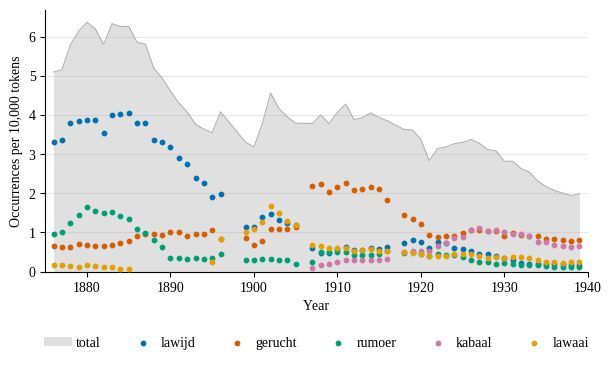

In [9]:
# Figure 4 of the paper, set in the paper's typeface (Tinos) when it is available.
from matplotlib import font_manager

for font in (Path("../../fonts/Tinos")).glob("*.ttf"):
    font_manager.fontManager.addfont(str(font))
plt.rcParams.update({"font.family": "serif", "font.serif": ["Tinos", "Times New Roman", "DejaVu Serif"],
                     "font.size": 10})

COLOURS = {"lawijd": "#0072B2", "gerucht": "#D55E00", "rumoer": "#009E73",
           "kabaal": "#CC79A7", "lawaai": "#E69F00"}            # Okabe-Ito, colour-blind safe

total = smoothed.sum(axis=1)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.fill_between(total.index, total, color="0.88", linewidth=0, label="total", zorder=1)
ax.plot(total.index, total, color="0.7", linewidth=0.8, zorder=1)
for term in CORE_TERMS:
    shown = smoothed[term] >= 0.05                               # leave out years in which a term is absent
    ax.scatter(smoothed.index[shown], smoothed.loc[shown, term], s=10, color=COLOURS[term], label=term, zorder=3)
ax.set_xlim(FIRST_YEAR - 1, LAST_YEAR + 1)
ax.set_ylim(bottom=0)
ax.set_xlabel("Year")
ax.set_ylabel("Occurrences per 10,000 tokens")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False, ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.2), handletextpad=0.3)
for ext in ("png", "pdf"):
    fig.savefig(FIG / f"term_frequencies_per_year.{ext}", dpi=300, bbox_inches="tight")